# UTS Graf Sains Data: Python Driver Neo4j dan Rekomendasi
**Nama / NIM:** *Halilatunnisa (24031554130)*  |  **Dataset:** RetailRocket (`events.csv`)

**Periode:** P1 (training) = 1-14 Juni 2015, P2 (testing) = 15-21 Juni 2015.

**Alur:** filter periode, impor P1 ke Neo4j, bentuk VSM User dan Item, pilih proyeksi, hitung similarity, rekomendasi KNN item-based, lalu evaluasi dengan P2.

**Reproducibility:** seed acak = 42.

## 2.1 No. 1: Penentuan dua periode waktu
Data mencakup 3 Mei - 18 September 2015 (contoh periode 2023/2024 di soal hanya contoh format). P1 dipilih dua minggu sebagai data latih agar riwayat interaksi cukup, dan P2 satu minggu tepat setelahnya sebagai data uji agar tidak ada kebocoran waktu (P2 selalu setelah P1). Kolom `timestamp` berupa epoch milidetik, dikonversi dengan `pd.to_datetime(unit="ms")`.

In [1]:
import pandas as pd

df = pd.read_csv("data/events.csv")
df["dt"] = pd.to_datetime(df["timestamp"], unit="ms")

P1 = ("2015-06-01", "2015-06-14")   # training
P2 = ("2015-06-15", "2015-06-21")   # testing

def filter_period(d, start, end):
    s = pd.Timestamp(start)
    e = pd.Timestamp(end) + pd.Timedelta(days=1)
    return d[(d["dt"] >= s) & (d["dt"] < e)]

train = filter_period(df, *P1)
test  = filter_period(df, *P2)

print("Train:", len(train), "event |", train.visitorid.nunique(), "visitor |", train.itemid.nunique(), "item")
print("Test :", len(test),  "event |", test.visitorid.nunique(),  "visitor |", test.itemid.nunique(),  "item")
print(train.event.value_counts())

Train: 278297 event | 148909 visitor | 76420 item
Test : 145976 event | 76996 visitor | 50854 item
event
view           269671
addtocart        6486
transaction      2140
Name: count, dtype: int64


## 2.1 No. 2: Simpan hasil filter
Hasil filter disimpan ke `data/events_train.csv` (P1) dan `data/events_test.csv` (P2). Hanya P1 yang diimpor ke Neo4j, sedangkan P2 dipakai sebagai kunci jawaban evaluasi di 2.2.

In [2]:
train.drop(columns="dt").to_csv("data/events_train.csv", index=False)
test.drop(columns="dt").to_csv("data/events_test.csv", index=False)
print("Tersimpan")

Tersimpan


## Koneksi dan impor ke Neo4j
Koneksi dibuat dengan `GraphDatabase.driver`. Constraint `UNIQUE` pada `Visitor.visitorId` dan `Item.itemId` mencegah simpul ganda dan mempercepat `MERGE`. Impor dilakukan per batch 5.000 baris (`UNWIND $batch`). Setiap event menjadi relasi bertipe: `view` menjadi `VIEWED`, `addtocart` menjadi `ADDED_TO_CART`, `transaction` menjadi `BOUGHT`. Sintaks `CALL (v, i, row)` dipakai agar sesuai Neo4j versi terbaru.

In [3]:
from neo4j import GraphDatabase
from tqdm.auto import tqdm

URI  = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", "password123")   
DB   = "neo4j"

driver = GraphDatabase.driver(URI, auth=AUTH)
driver.verify_connectivity()
print("Koneksi OK")

def create_constraints(session):
    session.run("CREATE CONSTRAINT visitor_id IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE")
    session.run("CREATE CONSTRAINT item_id IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE")

Koneksi OK


In [4]:
def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})

    WITH v, i, row
    CALL (v, i, row) {
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
    }
    """
    tx.run(cypher_query, batch=batch)

In [5]:
driver.execute_query("MATCH (n) DETACH DELETE n", database_=DB)

csv_path = "data/events_train.csv"
batch_size = 5000
total_rows = len(train)
total_chunks = (total_rows // batch_size) + 1

with driver.session(database=DB) as session:
    create_constraints(session)
    chunks = pd.read_csv(csv_path, chunksize=batch_size)
    for chunk in tqdm(chunks, total=total_chunks, desc="Mengimpor Batch Data"):
        chunk["transactionid"] = chunk["transactionid"].fillna("").astype(str)
        records = chunk.to_dict(orient="records")
        session.execute_write(import_batch, records)

print("Proses impor berhasil")

Mengimpor Batch Data:   0%|          | 0/56 [00:00<?, ?it/s]

Proses impor berhasil


## 2.1 No. 3: Komposisi subgraph
Query Cypher yang dipakai:
- `MATCH (n) RETURN labels(n) AS label, count(*)`: `MATCH (n)` mengambil semua simpul, `labels(n)` mengambil jenisnya, `count(*)` menghitung jumlah per jenis.
- `MATCH ()-[r]->() RETURN type(r), count(*)`: sama, tetapi untuk relasi.

**Hasil:** 148.909 simpul `Visitor`, 76.420 simpul `Item`; relasi `VIEWED` 269.671, `ADDED_TO_CART` 6.486, `BOUGHT` 2.140 (total 278.297, sama dengan jumlah event P1).

In [6]:
r, _, _ = driver.execute_query(
    "MATCH (n) RETURN labels(n) AS label, count(*) AS jumlah", database_=DB)
for x in r: print(x["label"], x["jumlah"])

r, _, _ = driver.execute_query(
    "MATCH ()-[r]->() RETURN type(r) AS tipe, count(*) AS jumlah", database_=DB)
for x in r: print(x["tipe"], x["jumlah"])

['Visitor'] 148909
['Item'] 76420
VIEWED 269671
ADDED_TO_CART 6486
BOUGHT 2140


## 2.1 No. 4 dan 5: Vector Space Modelling
Matriks interaksi dibangun dari P1 dengan bobot view = 1, addtocart = 2, transaction = 3, lalu dijumlahkan per pasangan user-item.

| | VSM User (user x item) | VSM Item (item x user) |
|---|---|---|
| Shape | 148.909 x 76.420 | 76.420 x 148.909 |
| Dimensi tiap vektor | 76.420 (item) | 148.909 (user) |
| nnz | 217.908 | 217.908 |
| Sparsity | 99,9981% | 99,9981% |
| Memori (sparse CSR) | 3,2 MB | 2,9 MB |

Kedua matriks saling transpose. nnz (217.908) lebih kecil dari jumlah event (278.297) karena beberapa event jatuh pada pasangan user-item yang sama. Sebanyak 81,5% user hanya berinteraksi dengan 1 item (rata-rata 1,46 item/user), sedangkan 56,2% item hanya disentuh 1 user (rata-rata 2,85 user/item).

In [7]:
import numpy as np
from scipy.sparse import csr_matrix

w = {"view": 1, "addtocart": 2, "transaction": 3}
t = train.copy()
t["w"] = t["event"].map(w)
agg = t.groupby(["visitorid", "itemid"])["w"].sum().reset_index()

u_idx = {u: i for i, u in enumerate(agg["visitorid"].unique())}
i_idx = {x: i for i, x in enumerate(agg["itemid"].unique())}
inv_u = {v: k for k, v in u_idx.items()}
inv_i = {v: k for k, v in i_idx.items()}

M = csr_matrix((agg["w"], (agg["visitorid"].map(u_idx), agg["itemid"].map(i_idx))),
               shape=(len(u_idx), len(i_idx)))

def info(name, A):
    n = A.shape[0] * A.shape[1]
    print(f"{name}: shape={A.shape}, nnz={A.nnz}, sparsity={1 - A.nnz/n:.6f}, "
          f"memori={(A.data.nbytes + A.indices.nbytes + A.indptr.nbytes)/1e6:.1f} MB")

info("VSM User (user x item)", M)
info("VSM Item (item x user)", M.T.tocsr())

user_deg = np.diff(M.indptr)              # jumlah item per user
item_deg = np.diff(M.T.tocsr().indptr)    # jumlah user per item
print("User: rata2 item/user =", user_deg.mean(), "| median =", np.median(user_deg),
      "| user dgn 1 item =", (user_deg == 1).mean())
print("Item: rata2 user/item =", item_deg.mean(), "| median =", np.median(item_deg),
      "| item dgn 1 user =", (item_deg == 1).mean())

VSM User (user x item): shape=(148909, 76420), nnz=217908, sparsity=0.999981, memori=3.2 MB
VSM Item (item x user): shape=(76420, 148909), nnz=217908, sparsity=0.999981, memori=2.9 MB
User: rata2 item/user = 1.4633635307469663 | median = 1.0 | user dgn 1 item = 0.814564599856288
Item: rata2 user/item = 2.851452499345721 | median = 1.0 | item dgn 1 user = 0.5618555352002094


### Perbandingan kedua proyeksi (dasar no. 6)
Sel ini menghitung batas atas jumlah sisi pada proyeksi user-user dan item-item (item dengan *d* user menghasilkan d(d-1)/2 pasangan user), jumlah simpul terisolasi, dan densitas.

In [8]:
# batas atas jumlah sisi di tiap proyeksi
pairs_uu = int((item_deg * (item_deg - 1) // 2).sum())   # user-user
pairs_ii = int((user_deg * (user_deg - 1) // 2).sum())   # item-item
print("Batas atas sisi user-user :", pairs_uu, "| simpul:", M.shape[0])
print("Batas atas sisi item-item :", pairs_ii, "| simpul:", M.shape[1])

# simpul terisolasi
B = M.copy(); B.data[:] = 1
iso_users = int(((B @ (item_deg > 1).astype(int)) == 0).sum())
iso_items = int(((B.T @ (user_deg > 1).astype(int)) == 0).sum())
print(f"User terisolasi: {iso_users} ({iso_users/M.shape[0]:.1%})")
print(f"Item terisolasi: {iso_items} ({iso_items/M.shape[1]:.1%})")

# densitas proyeksi (batas atas)
dens_uu = pairs_uu / (M.shape[0] * (M.shape[0] - 1) / 2)
dens_ii = pairs_ii / (M.shape[1] * (M.shape[1] - 1) / 2)
print("Densitas user-user:", dens_uu, "| item-item:", dens_ii)
print("Item terpopuler (jumlah user):", item_deg.max(), "| user teraktif (jumlah item):", user_deg.max())

Batas atas sisi user-user : 1714404 | simpul: 148909
Batas atas sisi item-item : 994236 | simpul: 76420
User terisolasi: 29216 (19.6%)
Item terisolasi: 37474 (49.0%)
Densitas user-user: 0.0001546337148285559 | item-item: 0.00034049528022717795
Item terpopuler (jumlah user): 925 | user teraktif (jumlah item): 356


### Plot networkx (sampel)
Karena graf penuh terlalu besar, plot memakai sampel 15 simpul acak (seed 42) dengan derajat >= 3. Biru = user, oranye = item. Sampel pertama: 75 simpul dan 60 sisi; sampel kedua: 78 simpul dan 64 sisi. Sisi yang lebih sedikit dari simpul menunjukkan graf terdiri dari komponen-komponen kecil berbentuk bintang yang saling terpisah, sesuai sparsity 99,998%.

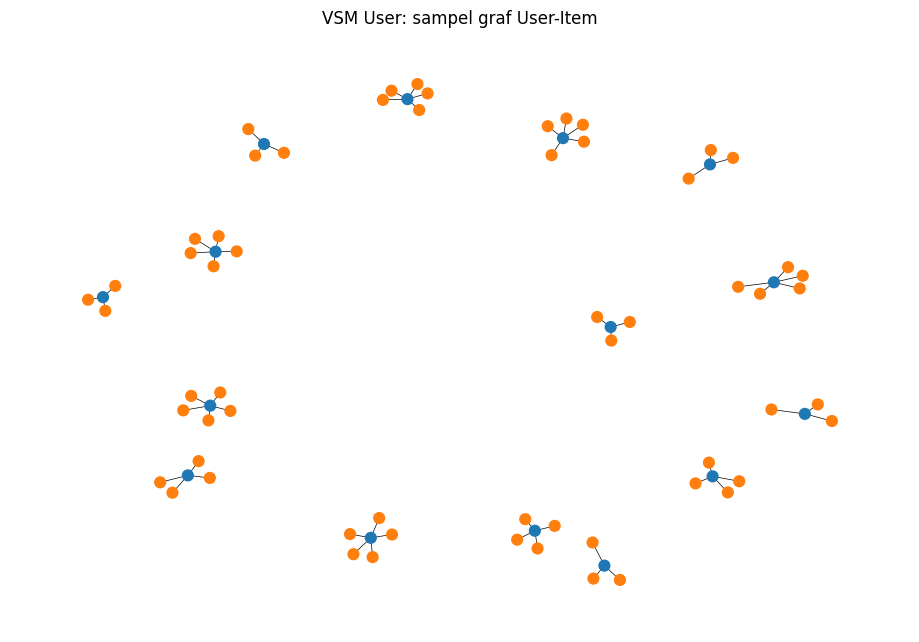

simpul: 75 sisi: 60


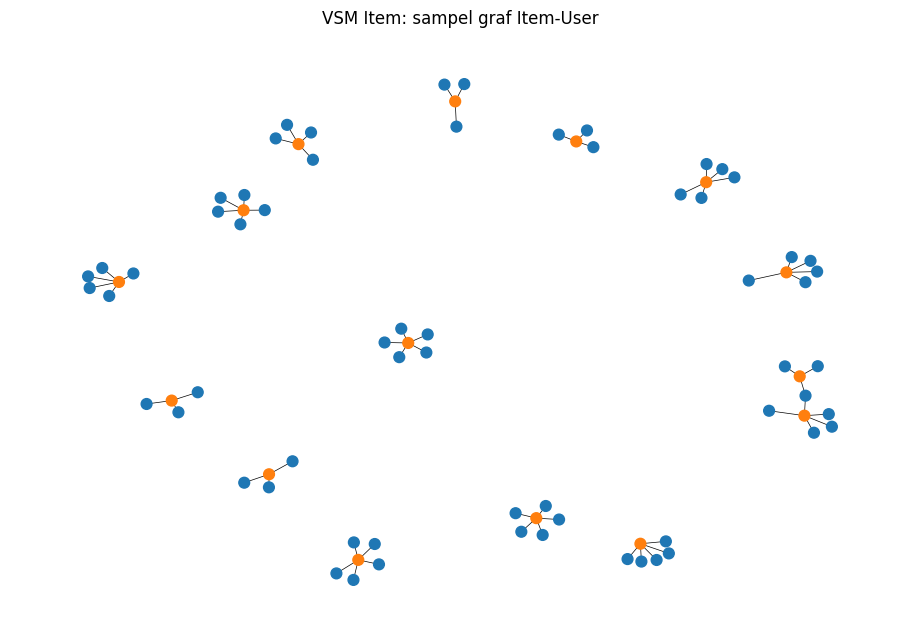

simpul: 78 sisi: 64


In [9]:
import networkx as nx
import matplotlib.pyplot as plt

def plot_sample(A, row_inv, col_inv, rows, title, row_color, col_color):
    G = nx.Graph()
    for r in rows:
        for c in A[r].nonzero()[1][:5]:
            G.add_edge(("r", row_inv[r]), ("c", col_inv[c]))
    colors = [row_color if n[0] == "r" else col_color for n in G.nodes]
    plt.figure(figsize=(9, 6))
    nx.draw_spring(G, node_size=60, node_color=colors, with_labels=False, width=0.5)
    plt.title(title); plt.show()
    print("simpul:", G.number_of_nodes(), "sisi:", G.number_of_edges())

rng = np.random.default_rng(42)
Mt = M.T.tocsr()

# sampel user dengan >= 3 item
sample_users = rng.choice(np.where(user_deg >= 3)[0], size=15, replace=False)
plot_sample(M, inv_u, inv_i, sample_users, "VSM User: sampel graf User-Item", "tab:blue", "tab:orange")

# sampel item dengan >= 3 user
sample_items = rng.choice(np.where(item_deg >= 3)[0], size=15, replace=False)
plot_sample(Mt, inv_i, inv_u, sample_items, "VSM Item: sampel graf Item-User", "tab:orange", "tab:blue")

## 2.1 No. 6: Proyeksi yang dipilih adalah Item-Item

| | User-User | Item-Item |
|---|---|---|
| Simpul | 148.909 | 76.420 |
| Batas atas sisi | 1.714.404 | 994.236 (42% lebih sedikit) |
| Densitas | 0,000155 | 0,000340 (2,2x lebih padat) |
| Simpul terisolasi | 19,6% | 49,0% |

**Efisiensi:** proyeksi item-item memiliki separuh simpul dan 42% lebih sedikit sisi. Proyeksi user-user didominasi hub: satu item dengan 925 user menyumbang sekitar 427 ribu pasangan (±25% seluruh sisi), sehingga banyak sisi hanya mencerminkan popularitas, bukan kemiripan selera.

**Efektivitas:** item-item menyisakan 49% item terisolasi (vs 19,6% user). Namun item tersebut hanya disentuh user yang berinteraksi dengan satu item, sehingga memang tidak ada sinyal kolaboratif yang bisa dipakai. Sel di bawah menunjukkan 63,0% user tetap bisa mendapat rekomendasi item-based.

**Keterbatasan:** cakupan rekomendasi terbatas akibat sparsity yang sangat tinggi.

In [10]:
Bi = M.copy(); Bi.data[:] = 1
item_connected = (Bi.T @ (user_deg > 1).astype(int)) > 0
user_covered = (Bi @ item_connected.astype(int)) > 0
print(f"User yang bisa dapat rekomendasi item-based: {user_covered.sum()} ({user_covered.mean():.1%})")

User yang bisa dapat rekomendasi item-based: 93747 (63.0%)


## 2.1 No. 7 dan 8: Similarity pada graf terproyeksi
Alur: (1) simpan jumlah relasi **sebelum** similarity, (2) hitung cosine similarity item acuan terhadap semua item, (3) tulis 5 teratas ke Neo4j sebagai relasi `SIMILAR`, (4) simpan jumlah relasi **sesudahnya**.

In [11]:
def snapshot():
    r, _, _ = driver.execute_query(
        "MATCH ()-[r]->() RETURN type(r) AS tipe, count(*) AS jumlah ORDER BY tipe", database_=DB)
    return {x["tipe"]: x["jumlah"] for x in r}

before = snapshot()
print("SEBELUM:", before)

SEBELUM: {'ADDED_TO_CART': 6486, 'BOUGHT': 2140, 'VIEWED': 269671}


### Perhitungan cosine similarity
Baris matriks item x user dinormalisasi (L2), sehingga hasil kali titik antar baris sama dengan cosine similarity. Item acuan adalah item terpopuler (ID 5411, 925 user). Hanya satu baris yang dihitung (1 x 76.420), sehingga hemat memori (matriks penuh 76.420 x 76.420 butuh sekitar 47 GB). Skor tertinggi hanya 0,23 karena irisan user antara item populer dan item niche sangat kecil.

In [12]:
from sklearn.preprocessing import normalize

X  = M.T.tocsr().astype(float)     
Xn = normalize(X)                   

ref = int(np.argmax(item_deg))       
ref_id = int(inv_i[ref])
print("Item acuan:", ref_id, "| jumlah user:", item_deg[ref])

sims = (Xn[ref] @ Xn.T).toarray().ravel()    
sims[ref] = -1                               
top = np.argsort(-sims)[:5]

for j in top:
    print(int(inv_i[j]), round(float(sims[j]), 4), "| user:", int(item_deg[j]))

Item acuan: 5411 | jumlah user: 925
33030 0.2348 | user: 55
89143 0.2101 | user: 12
33956 0.1488 | user: 18
459936 0.1427 | user: 15
358234 0.094 | user: 18


### No. 7a dan 7b: Top-5 dan tulis ke graf
- `MERGE (a)-[s:SIMILAR]->(b)`: membuat relasi hanya jika belum ada, jadi aman dijalankan ulang tanpa relasi ganda.
- `SET s.score = r.s`: menyimpan nilai similarity sebagai properti relasi.
- `ORDER BY score DESC LIMIT 5`: mengambil 5 similarity tertinggi (jawaban 7a). Outputnya membuktikan nilai sudah tersimpan di graf (7b).

Snapshot relasi: sebelum = VIEWED 269.671, ADDED_TO_CART 6.486, BOUGHT 2.140; sesudah = ditambah `SIMILAR` 5.

In [13]:
rows = [{"a": ref_id, "b": int(inv_i[j]), "s": float(sims[j])} for j in top]
driver.execute_query("""
UNWIND $rows AS r
MATCH (a:Item {itemId: r.a}), (b:Item {itemId: r.b})
MERGE (a)-[s:SIMILAR]->(b)
SET s.score = r.s, s.method = 'cosine'
""", rows=rows, database_=DB)

after = snapshot()
print("SESUDAH:", after)

r, _, _ = driver.execute_query("""
MATCH (a:Item {itemId: $id})-[s:SIMILAR]->(b:Item)
RETURN b.itemId AS item, s.score AS score ORDER BY score DESC LIMIT 5
""", id=ref_id, database_=DB)
for x in r: print(x["item"], x["score"])

SESUDAH: {'ADDED_TO_CART': 6486, 'BOUGHT': 2140, 'SIMILAR': 5, 'VIEWED': 269671}
33030 0.2347509182317878
89143 0.21013292020967145
33956 0.1488432607542691
459936 0.14272976241018348
358234 0.09402074024491681


## 2.1 No. 8: Graf sebelum dan sesudah similarity
Sebelum: item 5411 hanya terhubung ke visitor lewat relasi interaksi. Sesudah: muncul 5 relasi `SIMILAR` ke item-item yang paling mirip.

### Kondisi graf sebelum similarity
Query:
`MATCH (a:Item {itemId: 5411})<-[r]-(v:Visitor) RETURN a, r, v LIMIT 25`

![sebelum](img/sebelum_similarity.png)

### Kondisi graf sesudah similarity
Query:
`MATCH p=(a:Item {itemId: 5411})-[:SIMILAR]->(b:Item) RETURN p`

![sesudah](img/sesudah_similarity.png)

## 2.2 No. 1: Pemilihan user acak (reproducible)
Proses acak: `np.random.default_rng(42).choice(eligible)`, dengan daftar `eligible` diurutkan dahulu agar hasil sama di komputer mana pun. User layak jika punya >= 2 item di P1 dan minimal 1 item **baru** di P2 (yang belum ada di P1), karena item yang sudah pernah disentuh tidak direkomendasikan lagi. Item relevan = item P2 yang ada di katalog P1 dan belum pernah disentuh user tersebut.

In [14]:
SEED = 42
K = 5

def p1_of(u):
    """Himpunan item yang disentuh user u di P1."""
    ui = u_idx[u]
    return {inv_i[j] for j in M.indices[M.indptr[ui]:M.indptr[ui + 1]]}

relevant_by_user = {}
for u, grp in test[test["itemid"].isin(i_idx)].groupby("visitorid"):
    if u in u_idx:
        new_items = set(grp["itemid"]) - p1_of(u)
        if new_items:
            relevant_by_user[u] = new_items

eligible = sorted(u for u in relevant_by_user if user_deg[u_idx[u]] >= 2)
print("User layak:", len(eligible))

rng = np.random.default_rng(SEED)          
target_user = int(rng.choice(eligible))
relevant = relevant_by_user[target_user]

print("Target user:", target_user)
print("Item di P1 :", sorted(int(x) for x in p1_of(target_user)))
print("Item relevan di P2 (baru):", sorted(int(x) for x in relevant))

User layak: 1174
Target user: 138613
Item di P1 : [93657, 433059, 443461]
Item relevan di P2 (baru): [168823]


### 2.2 No. 1a: KNN item-based (k = 5)
Untuk setiap item yang pernah disentuh user di P1, diambil k = 5 item tetangga dengan cosine tertinggi. Skor kandidat = jumlah (bobot interaksi x similarity) dari semua tetangga yang menunjuk ke kandidat tersebut. Item yang sudah disentuh dibuang, lalu diambil top-5. Jika skor seri, item yang lebih populer diprioritaskan.

In [15]:
def recommend(user_id, k=5, top_n=5):
    row = M[u_idx[user_id]]
    items = row.indices                      
    weights = row.data.astype(float)         # bobot view=1, cart=2, buy=3

    S = (Xn[items] @ Xn.T).toarray()        
    S[np.arange(len(items)), items] = 0     

    scores = np.zeros(S.shape[1])
    for r in range(len(items)):
        nn = np.argpartition(-S[r], k)[:k]   
        scores[nn] += weights[r] * S[r, nn] 

    scores[items] = 0                     
    top_idx = np.lexsort((-item_deg, -scores))[:top_n]  
    order = [j for j in top_idx if scores[j] > 0]
    return [(int(inv_i[j]), float(scores[j])) for j in order]

rec = recommend(target_user, k=K, top_n=5)
for rank, (it, sc) in enumerate(rec, 1):
    print(rank, it, round(sc, 4))

1 284494 0.6388
2 314952 0.193
3 283003 0.128
4 139779 0.0905


### 2.2 No. 1b: 3 item yang diiklankan (k = 5)
Tiga item teratas dari daftar rekomendasi KNN. Evaluasi di bawah memakai top-5 penuh.

In [16]:
ads = [it for it, _ in rec[:3]]
print("3 item yang diiklankan untuk user", target_user, "(k=5):", ads)

3 item yang diiklankan untuk user 138613 (k=5): [284494, 314952, 283003]


## 2.2 No. 2: Evaluasi
- **Hit@5** = 1 jika minimal satu item relevan muncul di 5 teratas, selain itu 0.
- **NDCG@5** = DCG / IDCG, dengan DCG = Σ 1/log2(posisi + 1) untuk item relevan di top-5, dan IDCG adalah DCG pada urutan ideal.

**Hasil user terpilih (user 138613):** Hit@5 = 0 dan NDCG@5 = 0,0. Item relevan di P2 (168823) tidak muncul di daftar rekomendasi. Satu user hanya satu titik data, jadi hasil ini belum mewakili performa model secara umum.

In [19]:
def hit_ndcg(rec_ids, relevant, k=5):
    rec_ids = rec_ids[:k]
    hit = int(any(r in relevant for r in rec_ids))
    dcg = sum(1/np.log2(i + 2) for i, r in enumerate(rec_ids) if r in relevant)
    idcg = sum(1/np.log2(i + 2) for i in range(min(len(relevant), k)))
    return hit, (dcg / idcg if idcg > 0 else 0.0)

rec_ids = [it for it, _ in rec]
hit5, ndcg5 = hit_ndcg(rec_ids, relevant)
print("Rekomendasi top-5:", rec_ids)
print("Relevan (P2)    :", sorted(int(x) for x in relevant))
print("Hit@5  =", hit5)
print("NDCG@5 =", round(ndcg5, 4))

Rekomendasi top-5: [284494, 314952, 283003, 139779]
Relevan (P2)    : [168823]
Hit@5  = 0
NDCG@5 = 0.0


Catatan: daftar rekomendasi hanya berisi 4 item (bukan 5) karena tetangga item-item user ini yang memiliki similarity > 0 terbatas (data sangat sparse). Item dengan skor 0 tidak dimasukkan ke daftar.

### Evaluasi pada 500 user acak
Hasil rata-rata pada 500 user: **Hit@5 = 0,0440** dan **NDCG@5 = 0,0209**.

In [20]:
rng2 = np.random.default_rng(SEED)
sample = rng2.choice(eligible, size=min(500, len(eligible)), replace=False)

H, N = [], []
for u in tqdm(sample, desc="Evaluasi user"):
    r_ids = [it for it, _ in recommend(int(u), k=K, top_n=5)]
    h, n = hit_ndcg(r_ids, relevant_by_user[int(u)])
    H.append(h); N.append(n)

print(f"Jumlah user dievaluasi = {len(sample)}")
print(f"Rata-rata Hit@5  = {np.mean(H):.4f}")
print(f"Rata-rata NDCG@5 = {np.mean(N):.4f}")

Evaluasi user:   0%|          | 0/500 [00:00<?, ?it/s]

Jumlah user dievaluasi = 500
Rata-rata Hit@5  = 0.0440
Rata-rata NDCG@5 = 0.0209


## Kesimpulan dan keterbatasan
- Proyeksi item-item dipilih karena lebih kecil, lebih padat, dan tidak didominasi hub user.
- Pada 500 user acak, Hit@5 = 0,0440 (sekitar 22 user mendapat minimal 1 item benar) dan NDCG@5 = 0,0209. Nilai ini rendah dalam skala absolut, tetapi jauh di atas rekomendasi acak (peluang Hit@5 acak dari 76 ribu item di bawah 0,1%).
- NDCG@5 lebih kecil dari Hit@5 karena item yang benar, saat muncul, biasanya berada di posisi bawah daftar, sehingga mendapat diskon posisi.
- Penyebab nilai rendah: data sangat sparse (99,998%), mayoritas user hanya berinteraksi dengan 1 item, periode data pendek, dan hanya 63% user yang bisa dijangkau item-based.
- Keterbatasan: item P2 yang tidak ada di P1 tidak bisa direkomendasikan (cold-start), dan evaluasi hanya mencakup 1.174 user yang aktif di kedua periode.